# AML Transactions EDA — IBM Anti-Money-Laundering Dataset

Exploratory analysis of the [IBM Transactions for Anti-Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml)
dataset, stored locally under `dataset/`.

The dataset ships in two illicit-ratio variants (**HI** = higher illicit ratio, **LI** = lower)
and three sizes (**Small**, **Medium**, **Large**). Each variant has three files:

| File | Contents |
|---|---|
| `*_Trans.csv` | Transaction log: timestamp, from/to bank+account, amounts, currencies, payment format, `Is Laundering` label |
| `*_accounts.csv` | Account → Bank / Entity mapping |
| `*_Patterns.txt` | Ground-truth illicit "attempts" (cycles, fan-out, etc.), each a block of transaction rows |

File sizes range from ~34MB (`HI-Small_accounts.csv`) to ~17GB (`HI-Large_Trans.csv`), so the
transaction files are processed in **chunks** rather than loaded whole — this scales unchanged
from Small to Large by just changing `SIZE` below (Large will simply take longer).

In [1]:
%pip install -q pandas numpy matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\xavie\Y3S2\Big Data Archi\project\kaggle_venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Config: pick which dataset variant to analyze ---------------------------------
DATA_DIR = Path("../dataset")
PREFIX = "HI"      # "HI" (higher illicit ratio) or "LI" (lower illicit ratio)
SIZE = "Small"     # "Small", "Medium", or "Large" -- Large is ~17GB, expect a long chunked scan

TRANS_FILE = DATA_DIR / f"{PREFIX}-{SIZE}_Trans.csv"
ACCOUNTS_FILE = DATA_DIR / f"{PREFIX}-{SIZE}_accounts.csv"
PATTERNS_FILE = DATA_DIR / f"{PREFIX}-{SIZE}_Patterns.txt"

for f in (TRANS_FILE, ACCOUNTS_FILE, PATTERNS_FILE):
    size_mb = f.stat().st_size / 1e6
    print(f"{f}  ({size_mb:,.1f} MB)")

# --- Shared style: brand-neutral, colorblind-checked palette -----------------------
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781"}
SURFACE, PAGE, GRID, AXIS = "#fcfcfb", "#f9f9f7", "#e1e0d9", "#c3c2b7"
STATUS = {"good": "#0ca30c", "critical": "#d03b3b"}
CAT = {  # fixed categorical hue order -- assign by entity identity, never by rank
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "magenta": "#e87ba4", "green": "#008300", "violet": "#4a3aa7", "red": "#e34948",
}
CAT_ORDER = ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]

plt.rcParams.update({
    "figure.facecolor": PAGE, "axes.facecolor": SURFACE, "savefig.facecolor": PAGE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK["secondary"], "text.color": INK["primary"],
    "xtick.color": INK["muted"], "ytick.color": INK["muted"], "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
})

def style_ax(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linewidth=0.8, color=GRID)
    ax.title.set_color(INK["primary"])
    return ax


dataset\HI-Small_Trans.csv  (475.7 MB)
dataset\HI-Small_accounts.csv  (34.1 MB)
dataset\HI-Small_Patterns.txt  (0.3 MB)


## 1. Accounts

Small enough to load in full (tens of MB even for the Large variant).

In [3]:
accounts = pd.read_csv(ACCOUNTS_FILE)
print(accounts.shape)
print(accounts.dtypes)
print("\nMissing values:\n", accounts.isna().sum())
accounts.head()


(518581, 5)
Bank Name           str
Bank ID           int64
Account Number      str
Entity ID           str
Entity Name         str
dtype: object

Missing values:
 Bank Name         0
Bank ID           0
Account Number    0
Entity ID         0
Entity Name       0
dtype: int64


,Bank Name,Bank ID,Account Number,Entity ID,Entity Name
0,Portugal Bank #4507,331579,80B779D80,80062E240,Sole Proprietorship #50438
1,Canada Bank #27,210,809D86900,800C998A0,Corporation #33520
2,UK Bank #33,21884,80812BE00,800C47F50,Partnership #35397
3,Germany Bank #4815,32742,81047F300,80096F0B0,Corporation #48813
4,National Bank of Harrisburg,127390,80BD8CF00,800FB8760,Corporation #889


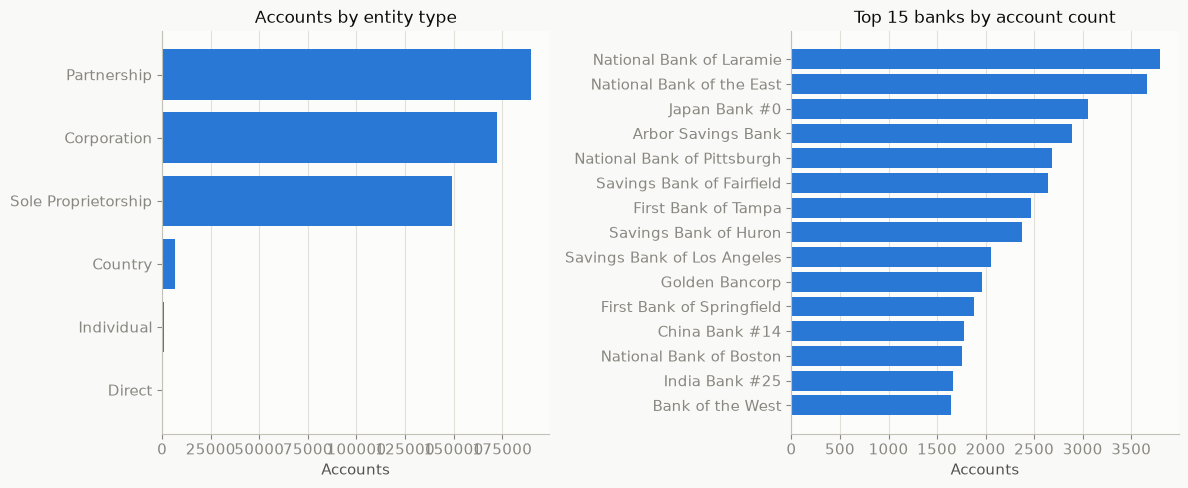

In [4]:
# Entity Name looks like "Corporation #33520" / "Sole Proprietorship #50438" -- pull out the type
accounts["Entity Type"] = accounts["Entity Name"].str.extract(r"^(.*?)\s*#\d+$")[0]

entity_counts = accounts["Entity Type"].value_counts()
bank_counts = accounts["Bank Name"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.barh(entity_counts.index[::-1], entity_counts.values[::-1], color=CAT["blue"])
ax.set_title("Accounts by entity type")
ax.set_xlabel("Accounts")
style_ax(ax, grid_axis="x")

ax = axes[1]
ax.barh(bank_counts.index[::-1], bank_counts.values[::-1], color=CAT["blue"])
ax.set_title("Top 15 banks by account count")
ax.set_xlabel("Accounts")
style_ax(ax, grid_axis="x")

fig.tight_layout()
plt.show()


## 2. Laundering patterns (ground truth)

`*_Patterns.txt` groups the illicit transactions into labeled "attempts" (e.g. `CYCLE`,
`FAN-OUT`, `SCATTER-GATHER`). Each block is delimited by `BEGIN/END LAUNDERING ATTEMPT - <TYPE>`
and contains the same 11 comma-separated fields as the transaction file, with no header.

In [5]:
def parse_patterns(path):
    begin_re = re.compile(r"BEGIN LAUNDERING ATTEMPT - ([A-Z\-]+)")
    attempts = []
    current_type, current_rows = None, 0
    with open(path, "r") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.startswith("BEGIN LAUNDERING ATTEMPT"):
                m = begin_re.search(line)
                current_type, current_rows = (m.group(1) if m else "UNKNOWN"), 0
            elif line.startswith("END LAUNDERING ATTEMPT"):
                attempts.append({"type": current_type, "n_transactions": current_rows})
                current_type = None
            elif line.strip():
                current_rows += 1
    return pd.DataFrame(attempts)

patterns = parse_patterns(PATTERNS_FILE)
print(f"{len(patterns)} laundering attempts, {patterns['n_transactions'].sum():,} illicit transactions total")
patterns.groupby("type")["n_transactions"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False)


370 laundering attempts, 3,209 illicit transactions total


,count,sum,mean
type,,,
GATHER-SCATTER,51,716,14.039216
SCATTER-GATHER,44,626,14.227273
STACK,43,466,10.837209
FAN-OUT,48,342,7.125000
FAN-IN,40,318,7.950000
CYCLE,54,287,5.314815
BIPARTITE,49,263,5.367347
RANDOM,41,191,4.658537


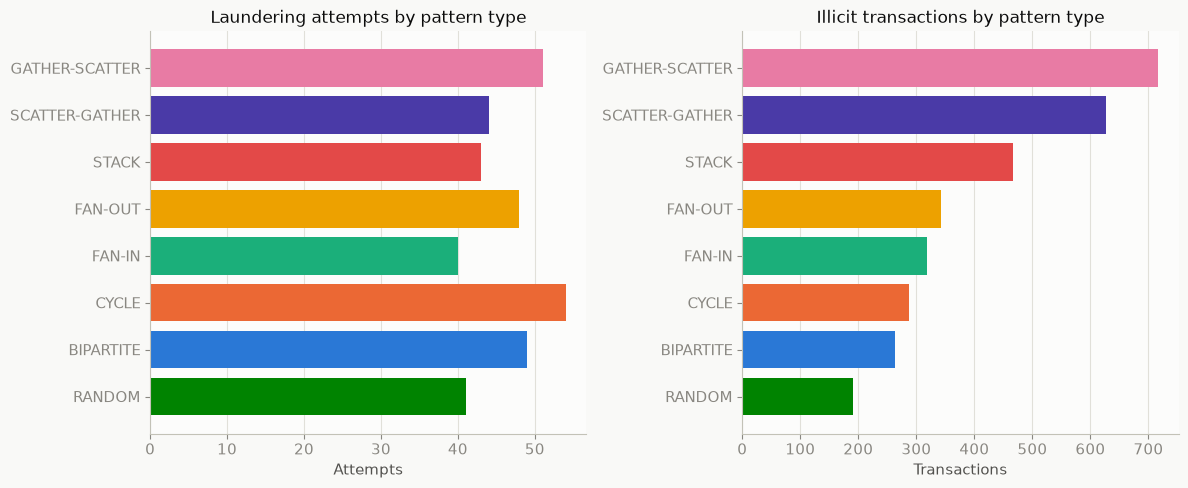

In [6]:
pattern_types = sorted(patterns["type"].unique())
color_map = {t: CAT[CAT_ORDER[i % len(CAT_ORDER)]] for i, t in enumerate(pattern_types)}

by_type = patterns.groupby("type")["n_transactions"].agg(attempts="count", transactions="sum")
by_type = by_type.sort_values("transactions", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.barh(by_type.index, by_type["attempts"], color=[color_map[t] for t in by_type.index])
ax.set_title("Laundering attempts by pattern type")
ax.set_xlabel("Attempts")
style_ax(ax, grid_axis="x")

ax = axes[1]
ax.barh(by_type.index, by_type["transactions"], color=[color_map[t] for t in by_type.index])
ax.set_title("Illicit transactions by pattern type")
ax.set_xlabel("Transactions")
style_ax(ax, grid_axis="x")

fig.tight_layout()
plt.show()


## 3. Transactions

The transaction file is read in **chunks** and reduced to running aggregates, so this cell's
cost scales with file size but not with available RAM -- the same code runs unchanged if
`SIZE` above is switched to `"Medium"` or `"Large"`.

A random ~2% sample of rows is kept (reservoir-style, chunk by chunk) for the plots that need
row-level detail (amount histograms).

In [7]:
TRANS_COLUMNS = ["Timestamp", "From Bank", "From Account", "To Bank", "To Account",
                  "Amount Received", "Receiving Currency", "Amount Paid", "Payment Currency",
                  "Payment Format", "Is Laundering"]

CHUNK_SIZE = 2_000_000
SAMPLE_FRAC = 0.02
SEED = 42

def scan_transactions(path, chunksize=CHUNK_SIZE, sample_frac=SAMPLE_FRAC, seed=SEED):
    rng = np.random.default_rng(seed)
    n_rows = 0
    is_laundering_counts = pd.Series(dtype="int64")
    payment_format_counts = pd.Series(dtype="int64")
    currency_counts = pd.Series(dtype="int64")
    self_txn = 0
    currency_mismatch = 0
    amount_sum = 0.0
    amount_min = np.inf
    amount_max = -np.inf
    daily = {}
    samples = []

    reader = pd.read_csv(path, header=0, names=TRANS_COLUMNS, chunksize=chunksize,
                          parse_dates=["Timestamp"])
    for chunk in reader:
        n_rows += len(chunk)
        is_laundering_counts = is_laundering_counts.add(chunk["Is Laundering"].value_counts(), fill_value=0)
        payment_format_counts = payment_format_counts.add(chunk["Payment Format"].value_counts(), fill_value=0)
        currency_counts = currency_counts.add(chunk["Payment Currency"].value_counts(), fill_value=0)
        self_txn += int((chunk["From Account"] == chunk["To Account"]).sum())
        currency_mismatch += int((chunk["Receiving Currency"] != chunk["Payment Currency"]).sum())

        amounts = chunk["Amount Paid"]
        amount_sum += amounts.sum()
        amount_min = min(amount_min, amounts.min())
        amount_max = max(amount_max, amounts.max())

        day = chunk["Timestamp"].dt.date
        grp = chunk.groupby(day).agg(count=("Amount Paid", "size"),
                                      amount=("Amount Paid", "sum"),
                                      laundering=("Is Laundering", "sum"))
        for idx, row in grp.iterrows():
            acc = daily.setdefault(idx, [0, 0.0, 0])
            acc[0] += row["count"]; acc[1] += row["amount"]; acc[2] += row["laundering"]

        mask = rng.random(len(chunk)) < sample_frac
        samples.append(chunk.loc[mask])

    sample_df = pd.concat(samples, ignore_index=True)
    daily_df = pd.DataFrame(
        [(d, *v) for d, v in sorted(daily.items())],
        columns=["date", "count", "amount", "laundering_count"],
    )

    stats = dict(n_rows=n_rows, is_laundering_counts=is_laundering_counts,
                 payment_format_counts=payment_format_counts, currency_counts=currency_counts,
                 self_txn=self_txn, currency_mismatch=currency_mismatch,
                 amount_sum=amount_sum, amount_min=amount_min, amount_max=amount_max,
                 daily=daily_df)
    return stats, sample_df

stats, sample_df = scan_transactions(TRANS_FILE)

print(f"Rows: {stats['n_rows']:,}")
print(f"Date range: {stats['daily']['date'].min()} .. {stats['daily']['date'].max()}")
print(f"Amount paid: min={stats['amount_min']:,.2f}  mean={stats['amount_sum']/stats['n_rows']:,.2f}  max={stats['amount_max']:,.2f}")
print(f"Self-transactions (from == to account): {stats['self_txn']:,} ({stats['self_txn']/stats['n_rows']:.2%})")
print(f"Currency mismatch (received != paid currency): {stats['currency_mismatch']:,} ({stats['currency_mismatch']/stats['n_rows']:.2%})")
print(f"Sample rows kept for detail plots: {len(sample_df):,}")


Rows: 5,078,345
Date range: 2022-09-01 .. 2022-09-18
Amount paid: min=0.00  mean=4,509,273.37  max=1,046,302,363,293.48
Self-transactions (from == to account): 591,212 (11.64%)
Currency mismatch (received != paid currency): 72,170 (1.42%)
Sample rows kept for detail plots: 101,326


### 3a. Class imbalance -- `Is Laundering`

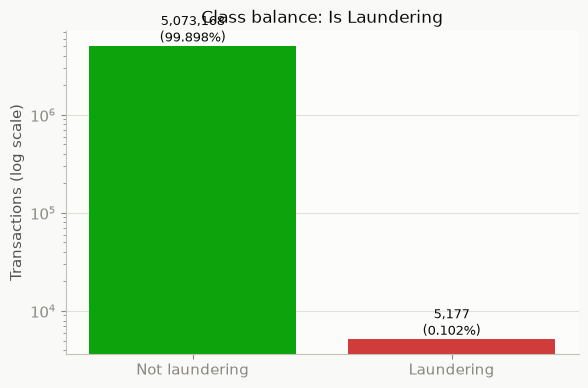

In [8]:
counts = stats["is_laundering_counts"].reindex([0, 1]).fillna(0).astype(int)
labels = ["Not laundering", "Laundering"]
colors = [STATUS["good"], STATUS["critical"]]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=colors)
ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class balance: Is Laundering")
style_ax(ax)
for b, v in zip(bars, counts.values):
    ax.annotate(f"{v:,}\n({v/counts.sum():.3%})", (b.get_x() + b.get_width() / 2, v),
                ha="center", va="bottom", color=INK["primary"], fontsize=9)
fig.tight_layout()
plt.show()


### 3b. Payment format & currency

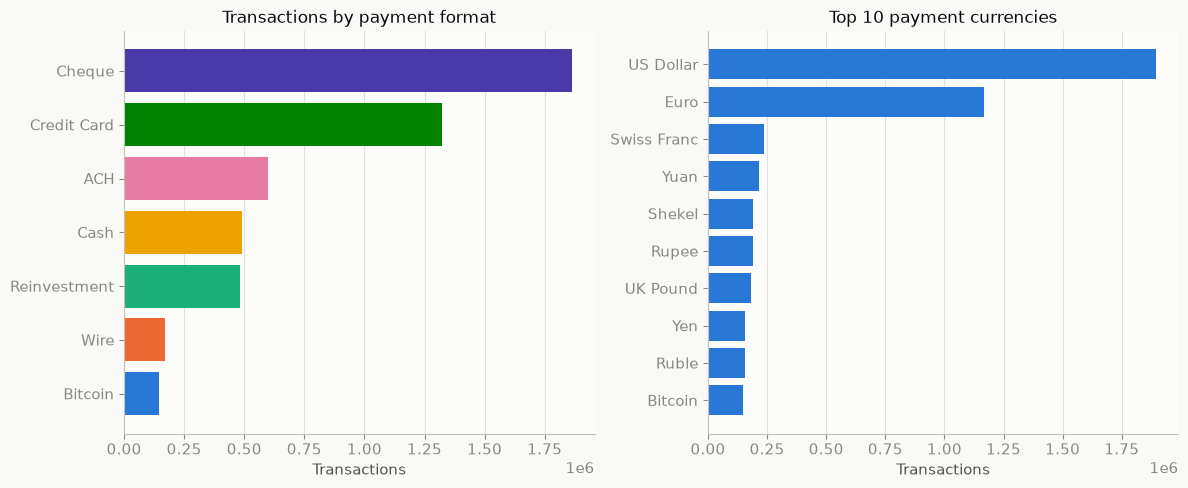

In [9]:
pf = stats["payment_format_counts"].sort_values(ascending=True)
pf_colors = [CAT[CAT_ORDER[i % len(CAT_ORDER)]] for i in range(len(pf))]

cur = stats["currency_counts"].sort_values(ascending=False)
cur_top = cur.head(10).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.barh(pf.index, pf.values, color=pf_colors)
ax.set_title("Transactions by payment format")
ax.set_xlabel("Transactions")
style_ax(ax, grid_axis="x")

ax = axes[1]
ax.barh(cur_top.index, cur_top.values, color=CAT["blue"])
ax.set_title("Top 10 payment currencies")
ax.set_xlabel("Transactions")
style_ax(ax, grid_axis="x")

fig.tight_layout()
plt.show()


### 3c. Transaction amounts

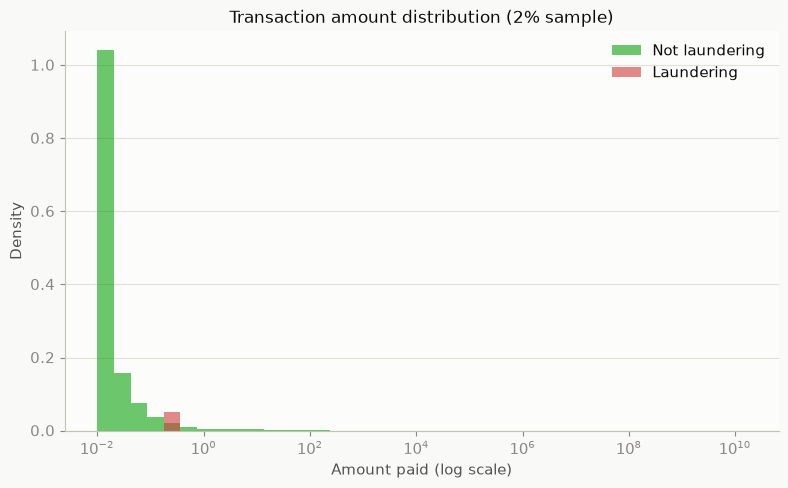

In [10]:
amt = sample_df["Amount Paid"].clip(lower=0.01)
bins = np.logspace(np.log10(amt.min()), np.log10(amt.max()), 40)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(amt[sample_df["Is Laundering"] == 0], bins=bins, color=STATUS["good"], alpha=0.6,
        label="Not laundering", density=True)
ax.hist(amt[sample_df["Is Laundering"] == 1], bins=bins, color=STATUS["critical"], alpha=0.6,
        label="Laundering", density=True)
ax.set_xscale("log")
ax.set_xlabel("Amount paid (log scale)")
ax.set_ylabel("Density")
ax.set_title("Transaction amount distribution (2% sample)")
ax.legend(frameon=False)
style_ax(ax)
fig.tight_layout()
plt.show()


### 3d. Transaction volume over time

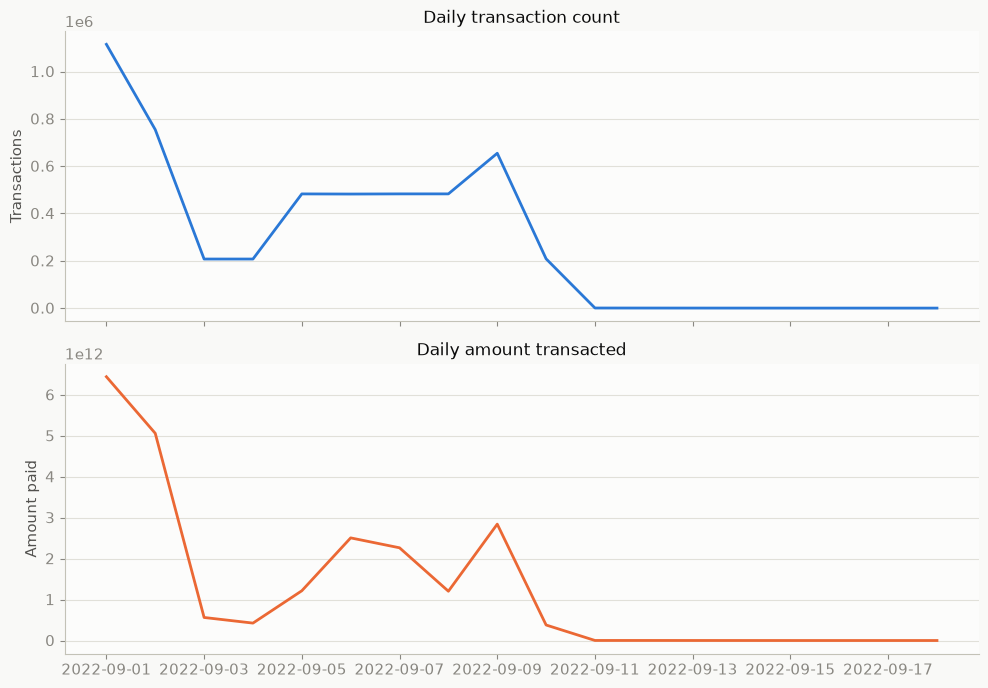

In [11]:
daily = stats["daily"]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax = axes[0]
ax.plot(daily["date"], daily["count"], color=CAT["blue"], linewidth=2)
ax.set_title("Daily transaction count")
ax.set_ylabel("Transactions")
style_ax(ax)

ax = axes[1]
ax.plot(daily["date"], daily["amount"], color=CAT["orange"], linewidth=2)
ax.set_title("Daily amount transacted")
ax.set_ylabel("Amount paid")
style_ax(ax)

fig.tight_layout()
plt.show()


### 3e. Risk indicators

How much do "structural" red flags (self-transfers, currency mismatches) actually associate
with the `Is Laundering` label, and does laundering rate vary by payment format?

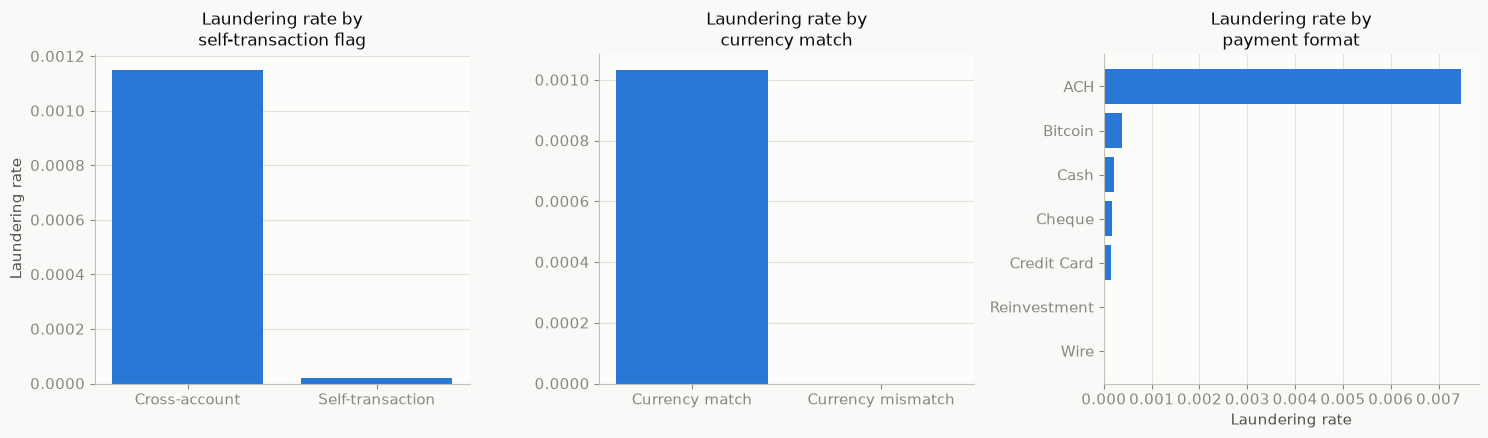

In [12]:
def scan_rates(path, chunksize=CHUNK_SIZE):
    rows = {"self_txn": [0, 0], "not_self_txn": [0, 0],
            "mismatch": [0, 0], "match": [0, 0]}
    pf_rows = {}
    reader = pd.read_csv(path, header=0, names=TRANS_COLUMNS, chunksize=chunksize)
    for chunk in reader:
        self_mask = chunk["From Account"] == chunk["To Account"]
        mismatch_mask = chunk["Receiving Currency"] != chunk["Payment Currency"]
        lab = chunk["Is Laundering"]

        for key, mask in (("self_txn", self_mask), ("not_self_txn", ~self_mask),
                           ("mismatch", mismatch_mask), ("match", ~mismatch_mask)):
            rows[key][0] += int(mask.sum())
            rows[key][1] += int((mask & (lab == 1)).sum())

        g = chunk.groupby("Payment Format")["Is Laundering"].agg(["count", "sum"])
        for fmt, r in g.iterrows():
            acc = pf_rows.setdefault(fmt, [0, 0])
            acc[0] += r["count"]; acc[1] += r["sum"]

    rate = {k: (v[1] / v[0] if v[0] else 0.0) for k, v in rows.items()}
    pf_rate = pd.Series({k: v[1] / v[0] for k, v in pf_rows.items() if v[0]}).sort_values()
    return rate, pf_rate

rate, pf_rate = scan_rates(TRANS_FILE)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
ax.bar(["Cross-account", "Self-transaction"], [rate["not_self_txn"], rate["self_txn"]],
       color=CAT["blue"])
ax.set_title("Laundering rate by\nself-transaction flag")
ax.set_ylabel("Laundering rate")
style_ax(ax)

ax = axes[1]
ax.bar(["Currency match", "Currency mismatch"], [rate["match"], rate["mismatch"]],
       color=CAT["blue"])
ax.set_title("Laundering rate by\ncurrency match")
style_ax(ax)

ax = axes[2]
ax.barh(pf_rate.index, pf_rate.values, color=CAT["blue"])
ax.set_title("Laundering rate by\npayment format")
ax.set_xlabel("Laundering rate")
style_ax(ax, grid_axis="x")

fig.tight_layout()
plt.show()


## 4. Summary

Findings from running this notebook against `HI-Small` (5,078,345 transactions,
2022-09-01 to 2022-09-18):

- **Class balance:** 5,177 laundering transactions out of 5,078,345 total
  (0.102% positive rate). 370 laundering attempts span 3,209 of those rows
  (~62%) -- the remaining ~38% of `Is Laundering=1` rows are not part of any
  named attempt in `Patterns.txt`. (`LI` variant not yet run -- expect a lower
  positive rate given the dataset's "low illicit ratio" framing.)
- **Payment format is the strongest transaction-level signal, by far.**
  Laundering rate by format: `ACH` 0.746% (**~7.3x** the base rate) --
  `Bitcoin` 0.038%, `Cash` 0.022%, `Cheque` 0.017%, `Credit Card` 0.016%, all
  near or below the 0.102% base rate; `Reinvestment` and `Wire` had **zero**
  laundering transactions in this sample. ACH dominates to the point that it
  should be the primary transaction-level feature, well ahead of self-transfer
  or currency-mismatch flags.
- **Self-transactions and currency mismatches are *not* positive indicators
  here -- this contradicts the naive assumption going into this EDA.**
  Self-transactions (`From Account == To Account`) are 11.64% of all rows but
  have a laundering rate of only 0.0037%, *lower* than cross-account transfers
  (0.115%). Currency-mismatched transactions are 1.42% of rows and have a
  laundering rate of **0%** -- none of the 5,177 labeled laundering
  transactions involve a currency mismatch. Both flags should be dropped from
  the rule-based risk score's positive-weight terms (see pipeline plan §4.3);
  keep them as diagnostic/explanatory features but don't reward them as risk.
- **Which pattern types dominate:** `GATHER-SCATTER` and `SCATTER-GATHER` carry
  the most illicit transactions (716 and 626 respectively) and the largest
  average attempt size (~14 transactions/attempt), roughly 2-3x the size of
  `CYCLE`/`BIPARTITE`/`RANDOM` attempts (~5 transactions/attempt on average).
  Multi-hop fan-in/fan-out patterns are where most illicit *volume* sits, even
  though `CYCLE` has the most individual attempts (54).
- **Amount is heavily currency-denomination-skewed, not usable raw.** Mean
  `Amount Paid` is ~$4.5M but the max exceeds $1 trillion -- this is almost
  entirely a currency-denomination artifact (e.g. Yen/Rupiah face values), not
  real-dollar outliers. Any "amount outlier" feature must use `amount_usd`
  (post FX-conversion), never the raw `Amount Paid`/`Amount Received` columns.

To analyze the full `Large` files (~17GB), this notebook's chunked approach already scales,
but for repeated / interactive work at that scale, consider pushing the aggregation into
Spark or DuckDB rather than pandas.